# Yosemite temperatures: can a TCN + XGBoost + ridge blend beat the RBF model?

The RBF notebook's best model (ridge on an RBF every 2 days + 12 RBFs around the clock) scored **R² 0.931 on
whole days it never saw**. This notebook tries to beat it with the same inputs (time only, no other sensors):

| Model | Idea |
|---|---|
| **RBF baseline** | The RBF notebook's best model, unchanged, re-scored here so the comparison is like for like |
| **RBF+ ridge** | Same RBFs plus better transforms of time (below) |
| **XGBoost** | Trees on the date, hour and time of year; `reg_lambda` is an L2 (ridge) penalty on the leaf values |
| **TCN** | A temporal convolutional network that fills each missing day from the readings on the days around it; `weight_decay` is an L2 (ridge) penalty on its weights |
| **Ridge blend** | Ridge regression on the four models' predictions |
| **TCN forecast** | A second TCN that predicts a whole day from only the 7 days before it (a forecasting test, at the end) |

**Transforms.** Time of day and time of year go in as sines and cosines (so 23:59 sits next to 00:00 and 31 Dec
next to 1 Jan), with 3 daily harmonics for the cycle's lopsided shape (quick morning warm-up, slow evening
cool-down) and products of daily × yearly terms so the daily swing can be bigger in summer. Each reading is timed
at the centre of its 5-minute window. The TCN also gets a straight line drawn across each gap and the distance in
hours to the nearest known reading on each side.

**Fair test.** Same held-out days as the RBF notebook: every 7th day (`day % 7 == 3`) is the **test set**, used
once at the very end. Choosing alpha, early stopping and fitting the blend use a separate **validation set**
(`day % 7 == 5`). Scores are R² on all 5-minute readings of the test days. (The RBF notebook's 0.931 was chosen
by searching on its held-out days, so it was slightly optimistic; the baseline row here does not have that edge.)

Colab already has numpy, scikit-learn, xgboost and torch. The TCN runs on CPU in about 10 minutes, faster on a
GPU runtime (Runtime → Change runtime type).

In [1]:
import os, time, copy, urllib.request
import numpy as np
import matplotlib.pyplot as plt

# Data: the repo's gitignored data/ folder if run from the repo, else a folder next to the notebook (works in Colab).
DATA_DIR = os.path.abspath('../../data/yosemite_village' if os.path.isdir('../../data') else 'yosemite_village')
os.makedirs(DATA_DIR, exist_ok=True)
paths = []
for y in range(2011, 2017):
    f = 'CRNS0101-05-%d-CA_Yosemite_Village_12_W.txt' % y
    paths.append(os.path.join(DATA_DIR, f))
    if not os.path.exists(paths[-1]):
        print('downloading', f)
        urllib.request.urlretrieve('https://www.ncei.noaa.gov/pub/data/uscrn/products/subhourly01/%d/%s' % (y, f),
                                   paths[-1])

data = np.vstack([np.loadtxt(p, usecols=[1, 2, 8]) for p in paths])  # UTC date, UTC time (HHmm, end of window), temp
data = data[data[:, 2] > -1000]                                      # drop missing (-9999)
ymd = data[:, 0].astype(int)
dates = np.array(['%04d-%02d-%02d' % (v // 10000, v // 100 % 100, v % 100) for v in ymd], dtype='datetime64[D]')
minute = (data[:, 1] // 100) * 60 + data[:, 1] % 100
# Time of each reading = centre of its 5-minute window, in days since 1 Jan 2011 (UTC).
t = (dates - np.datetime64('2011-01-01')).astype(float) + (minute - 2.5) / 1440.0
keep = t >= 0
t, temp = t[keep], data[keep, 2]

# Hourly grid: mean of the readings in each hour (NaN where an hour has none). Models are fitted on these
# (about one row per hour, like the RBF notebook) and scored on the 5-minute readings.
hour = np.floor(t * 24).astype(int)
N = hour.max() + 1
cnt = np.bincount(hour, minlength=N)
T_hour = np.full(N, np.nan)
T_hour[cnt > 0] = np.bincount(hour, weights=temp, minlength=N)[cnt > 0] / cnt[cnt > 0]
t_hour = (np.arange(N) + 0.5) / 24
obs_h = ~np.isnan(T_hour)

# Split by whole UTC day: test = day % 7 == 3 (as in the RBF notebook), validation = day % 7 == 5, train = the rest.
TEST, VAL = 3, 5
day_r, day_h = np.floor(t).astype(int), np.arange(N) // 24
te_r, va_r = day_r % 7 == TEST, day_r % 7 == VAL
te_h, va_h = day_h % 7 == TEST, day_h % 7 == VAL
tr_h = ~(te_h | va_h)
print('%d readings, %d hours; %d test days, %d validation days'
      % (len(temp), N, len(np.unique(day_r[te_r])), len(np.unique(day_r[va_r]))))


def r2(y, p):
    return 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)


def score(name, y, p):
    print('%-32s R^2 = %.3f   RMSE = %.2f °C' % (name, r2(y, p), np.sqrt(np.mean((y - p) ** 2))))

630854 readings, 52608 hours; 313 test days, 313 validation days


## Transforms and the two ridge models

In [2]:
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.linear_model import Ridge

YEAR = 365.2425


def harmonics(t):
    # Time of day and time of year as sines and cosines. Three daily harmonics give the cycle its lopsided shape;
    # the daily x yearly products let the daily swing grow in summer and shrink in winter.
    d, a = 2 * np.pi * (t % 1.0), 2 * np.pi * t / YEAR
    cols = [f(k * d) for k in (1, 2, 3) for f in (np.sin, np.cos)]
    cols += [f(k * a) for k in (1, 2) for f in (np.sin, np.cos)]
    cols += [f(d) * g(a) for f in (np.sin, np.cos) for g in (np.sin, np.cos)]
    return np.column_stack(cols)                     # 14 columns


def slow_rbfs(t, spacing, width=1.0):
    centres = np.arange(-spacing, 2200 + spacing, spacing).reshape(-1, 1)
    return rbf_kernel(t.reshape(-1, 1), centres, gamma=1.0 / (2 * (width * spacing) ** 2))


def rbf_baseline_features(t):
    # The RBF notebook's best model, unchanged: 12 RBFs around the clock + an RBF every 2 days, width 1.
    ang, c = 2 * np.pi * (t % 1.0), 2 * np.pi * np.arange(12) / 12
    daily = rbf_kernel(np.c_[np.cos(ang), np.sin(ang)], np.c_[np.cos(c), np.sin(c)],
                       gamma=1.0 / (2 * (2 * np.pi / 12) ** 2))
    return np.hstack([daily, slow_rbfs(t, 2.0)])


def rbf_plus_features(t):
    # Harmonics + the same RBF every 2 days + the first two daily harmonics multiplied by an RBF every 30 days,
    # so the shape and size of the daily cycle can drift through the year, not just the level.
    h = harmonics(t)
    coarse = slow_rbfs(t, 30.0)
    swing = np.hstack([h[:, [i]] * coarse for i in range(4)])
    return np.hstack([h, slow_rbfs(t, 2.0), swing])


def fit_ridge(feats, alpha, hours):
    rows = hours & obs_h
    return Ridge(alpha=alpha).fit(feats(t_hour[rows]), T_hour[rows])


def ridge_predict(model, feats, t, chunk=20000):
    # predict in chunks so the big feature matrix is never held all at once
    return np.concatenate([model.predict(feats(t[i:i + chunk])) for i in range(0, len(t), chunk)])


t0 = time.time()
# Stage A: fit on train days, predict validation days (for choosing alpha and fitting the blend).
p_base_va = ridge_predict(fit_ridge(rbf_baseline_features, 1e-3, tr_h), rbf_baseline_features, t[va_r])
score('RBF baseline, validation', temp[va_r], p_base_va)
best = None
for alpha in [1e-3, 1e-2, 1e-1, 1.0]:
    p = ridge_predict(fit_ridge(rbf_plus_features, alpha, tr_h), rbf_plus_features, t[va_r])
    score('RBF+ alpha %g, validation' % alpha, temp[va_r], p)
    if best is None or r2(temp[va_r], p) > best[0]:
        best = (r2(temp[va_r], p), alpha, p)
alpha_plus, p_plus_va = best[1], best[2]

# Stage B: refit on train + validation days, predict test days.
p_base_te = ridge_predict(fit_ridge(rbf_baseline_features, 1e-3, tr_h | va_h), rbf_baseline_features, t[te_r])
p_plus_te = ridge_predict(fit_ridge(rbf_plus_features, alpha_plus, tr_h | va_h), rbf_plus_features, t[te_r])
print('RBF+ alpha chosen: %g   (%.0f s)' % (alpha_plus, time.time() - t0))

RBF baseline, validation         R^2 = 0.933   RMSE = 1.99 °C


RBF+ alpha 0.001, validation     R^2 = 0.938   RMSE = 1.90 °C


RBF+ alpha 0.01, validation      R^2 = 0.940   RMSE = 1.88 °C


RBF+ alpha 0.1, validation       R^2 = 0.937   RMSE = 1.92 °C


RBF+ alpha 1, validation         R^2 = 0.929   RMSE = 2.05 °C


RBF+ alpha chosen: 0.01   (53 s)


## XGBoost (L2 / ridge penalty on the leaves)

In [3]:
import xgboost as xgb


def tree_features(t):
    # Trees split on raw numbers, so give them the date itself (to find weather spells), the hour of day and the
    # day of year, plus the same periodic transforms.
    return np.column_stack([t, (t % 1.0) * 24, t % YEAR, harmonics(t)])


params = dict(n_estimators=5000, learning_rate=0.03, max_depth=8, min_child_weight=5, subsample=0.8,
              colsample_bytree=0.8, reg_lambda=10.0, tree_method='hist')   # reg_lambda = L2 (ridge) penalty
rows_tr, rows_va = tr_h & obs_h, va_h & obs_h
t0 = time.time()
xgb_A = xgb.XGBRegressor(early_stopping_rounds=200, **params)
xgb_A.fit(tree_features(t_hour[rows_tr]), T_hour[rows_tr],
          eval_set=[(tree_features(t_hour[rows_va]), T_hour[rows_va])], verbose=False)
p_xgb_va = xgb_A.predict(tree_features(t[va_r]))
score('XGBoost, validation', temp[va_r], p_xgb_va)

params['n_estimators'] = xgb_A.best_iteration + 1
rows_B = (tr_h | va_h) & obs_h
xgb_B = xgb.XGBRegressor(**params).fit(tree_features(t_hour[rows_B]), T_hour[rows_B])
p_xgb_te = xgb_B.predict(tree_features(t[te_r]))
print('trees: %d   (%.0f s)' % (params['n_estimators'], time.time() - t0))

XGBoost, validation              R^2 = 0.922   RMSE = 2.14 °C


trees: 4998   (54 s)


## TCN that fills in missing days

The input is the hourly temperature series with the unseen days blanked out. During training, random whole
days are blanked as well and the network learns to fill them back in; the loss is only on those blanked hours.
Convolutions look both ways (non-causal), with dilations 1–32 giving each hour about ±5 days of context. The
network starts from the straight line across the gap and learns the correction. It only ever sees temperatures
from days the other models were also fitted on.

In [4]:
import torch
import torch.nn as nn

torch.manual_seed(0)
rng = np.random.default_rng(0)
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
mu, sd = np.nanmean(T_hour[tr_h]), np.nanstd(T_hour[tr_h])
z = np.nan_to_num((T_hour - mu) / sd)
H = harmonics(t_hour).astype(np.float32)


def tcn_input(sl, known):
    # Channels: reading (0 where unseen), seen flag, straight line across each gap, hours since / until the
    # nearest seen reading (in days, capped at 3), then the 14 harmonics.
    zs, pos = z[sl], np.arange(len(known))
    idx = np.flatnonzero(known)
    line = np.interp(pos, idx, zs[idx])
    i = np.searchsorted(idx, pos)
    before = np.where(known, 0, np.clip(pos - idx[np.clip(i - 1, 0, len(idx) - 1)], 0, 72)) / 24
    after = np.where(known, 0, np.clip(idx[np.clip(i, 0, len(idx) - 1)] - pos, 0, 72)) / 24
    x = np.column_stack([np.where(known, zs, 0), known, line, before, after]).astype(np.float32)
    return np.hstack([x, H[sl]]).T                   # channels x hours


class Block(nn.Module):
    def __init__(self, c, d, p):
        super().__init__()
        self.net = nn.Sequential(nn.Conv1d(c, c, 3, padding=d, dilation=d), nn.GELU(), nn.Dropout(p),
                                 nn.Conv1d(c, c, 3, padding=d, dilation=d), nn.GELU(), nn.Dropout(p))

    def forward(self, x):
        return x + self.net(x)


class TCN(nn.Module):
    def __init__(self, c_in, c=48, dilations=(1, 2, 4, 8, 16, 32), p=0.1):
        super().__init__()
        self.net = nn.Sequential(nn.Conv1d(c_in, c, 1), *[Block(c, d, p) for d in dilations], nn.Conv1d(c, 1, 1))

    def forward(self, x):
        return x[:, 2] + self.net(x).squeeze(1)      # correction to the straight-line fill (channel 2)


L = 24 * 21                                          # training windows of 3 weeks


def batch(avail, B=16):
    # Random windows; in each, blank about 1 day in 7 at random and ask for those hours back.
    X, Y, M = [], [], []
    while len(X) < B:
        s = int(rng.integers(0, N - L))
        sl = slice(s, s + L)
        days = np.unique(day_h[sl])
        hide = np.isin(day_h[sl], days[rng.random(len(days)) < 1 / 7])
        known = avail[sl] & obs_h[sl] & ~hide
        target = hide & avail[sl] & obs_h[sl]
        if target.sum() == 0 or known.sum() < 24:
            continue
        X.append(tcn_input(sl, known)); Y.append(z[sl]); M.append(target)
    as_t = lambda a: torch.tensor(np.stack(a), dtype=torch.float32, device=dev)
    return as_t(X), as_t(Y), as_t(M)


def tcn_predict(model, known):
    # Run the whole six-year series in one pass; returns °C for every hour.
    model.eval()
    with torch.no_grad():
        out = model(torch.tensor(tcn_input(slice(0, N), known)[None], device=dev))[0].cpu().numpy()
    model.train()
    return out * sd + mu


tcn = TCN(5 + H.shape[1]).to(dev)
opt = torch.optim.Adam(tcn.parameters(), lr=2e-3, weight_decay=1e-4)   # weight_decay = L2 (ridge) penalty
known_A = tr_h & obs_h                               # stage A: validation and test days stay blank
best, best_state, bad, t0 = -np.inf, None, 0, time.time()
for epoch in range(40):
    for step in range(100):
        X, Y, M = batch(tr_h)
        loss = (((tcn(X) - Y) ** 2) * M).sum() / M.sum()
        opt.zero_grad(); loss.backward(); opt.step()
    r2_va = r2(temp[va_r], np.interp(t[va_r], t_hour, tcn_predict(tcn, known_A)))
    print('epoch %2d  train loss %.3f  validation R^2 %.3f  (%.0f s)' % (epoch, loss.item(), r2_va, time.time() - t0))
    if r2_va > best:
        best, best_state, bad = r2_va, copy.deepcopy(tcn.state_dict()), 0
    else:
        bad += 1
        if bad == 6:                                 # early stopping
            break
tcn.load_state_dict(best_state)

p_tcn_va = np.interp(t[va_r], t_hour, tcn_predict(tcn, known_A))
# Stage B: same network, now also shown the validation days; only the test days are blank.
p_tcn_te = np.interp(t[te_r], t_hour, tcn_predict(tcn, (tr_h | va_h) & obs_h))
score('TCN, validation', temp[va_r], p_tcn_va)

epoch  0  train loss 0.076  validation R^2 0.961  (14 s)


epoch  1  train loss 0.085  validation R^2 0.969  (27 s)


epoch  2  train loss 0.052  validation R^2 0.959  (40 s)


epoch  3  train loss 0.112  validation R^2 0.970  (52 s)


epoch  4  train loss 0.073  validation R^2 0.966  (65 s)


...

epoch 17  train loss 0.047  validation R^2 0.970  (229 s)


epoch 18  train loss 0.044  validation R^2 0.972  (243 s)


epoch 19  train loss 0.066  validation R^2 0.968  (256 s)


epoch 20  train loss 0.067  validation R^2 0.972  (270 s)


TCN, validation                  R^2 = 0.972   RMSE = 1.28 °C


## Ridge blend, then the test set (used once)

In [5]:
names = ['RBF baseline (RBF notebook)', 'RBF+ ridge', 'XGBoost', 'TCN']
P_va = np.column_stack([p_base_va, p_plus_va, p_xgb_va, p_tcn_va])
P_te = np.column_stack([p_base_te, p_plus_te, p_xgb_te, p_tcn_te])
blend = Ridge(alpha=1.0, positive=True).fit(P_va, temp[va_r])
p_blend_te = blend.predict(P_te)
print('blend weights:', {n: round(float(w), 3) for n, w in zip(names, blend.coef_)},
      ' intercept %.2f' % blend.intercept_)

print('\nTEST days (every 7th day, never used for fitting or choosing anything), all 5-minute readings:')
for n, p in zip(names, P_te.T):
    score(n, temp[te_r], p)
score('Ridge blend of all four', temp[te_r], p_blend_te)

blend weights: {'RBF baseline (RBF notebook)': 0.0, 'RBF+ ridge': 0.0, 'XGBoost': 0.105, 'TCN': 0.916}  intercept -0.20

TEST days (every 7th day, never used for fitting or choosing anything), all 5-minute readings:
RBF baseline (RBF notebook)      R^2 = 0.931   RMSE = 2.02 °C
RBF+ ridge                       R^2 = 0.936   RMSE = 1.94 °C
XGBoost                          R^2 = 0.914   RMSE = 2.26 °C
TCN                              R^2 = 0.970   RMSE = 1.33 °C
Ridge blend of all four          R^2 = 0.970   RMSE = 1.33 °C


## Forecasting test: predict a day from the past only

Everything above *fills in* a missing day with known days on both sides. Here a second TCN (same architecture)
**forecasts**: it sees the 7 days before a day and nothing after, and predicts all 24 hours of that day. The
calendar (time of day, time of year) is known in advance, so those inputs stay. Test days are never shown to it,
not even as history; it is trained on train days, early-stopped on validation days, and scored once on the same
test days (skipping the very first test day, which has no 7-day history).

The baseline is **persistence**: "tomorrow at 3 pm will be what it was today at 3 pm". The RBF model cannot
forecast at all: its bumps fall to zero past the last day it was fitted on.

In [6]:
first = 7                                            # need 7 days of history
all_days = np.arange(first, N // 24)
fc_train_days = all_days[(all_days % 7 != TEST) & (all_days % 7 != VAL)]
fc_val_days, fc_test_days = all_days[all_days % 7 == VAL], all_days[all_days % 7 == TEST]
fc_va_r, fc_te_r = va_r & (day_r >= first), te_r & (day_r >= first)
fc_avail = ~te_h                                     # test days are never shown, even as history
LF = 24 * 8                                          # 7 days of history + the day to forecast


def fc_window(d):
    sl = slice((d - 7) * 24, (d + 1) * 24)
    known = fc_avail[sl] & obs_h[sl]
    known[-24:] = False                              # the day being forecast is blank, and nothing comes after it
    return tcn_input(sl, known)


def fc_batch(B=16):
    days = rng.choice(fc_train_days, B)
    X = np.stack([fc_window(d) for d in days])
    Y = np.stack([z[(d - 7) * 24:(d + 1) * 24] for d in days])
    M = np.stack([obs_h[(d - 7) * 24:(d + 1) * 24] & (np.arange(LF) >= LF - 24) for d in days])
    as_t = lambda a: torch.tensor(a, dtype=torch.float32, device=dev)
    return as_t(X), as_t(Y), as_t(M)


def fc_predict(model, days):
    # Forecast the 24 hours of each day from its 7-day history; returns an hourly °C array (NaN elsewhere).
    model.eval()
    with torch.no_grad():
        out = np.concatenate([model(torch.tensor(np.stack([fc_window(d) for d in days[i:i + 256]]), device=dev))
                              [:, -24:].cpu().numpy() for i in range(0, len(days), 256)])
    model.train()
    full = np.full(N, np.nan)
    full[(days[:, None] * 24 + np.arange(24)).ravel()] = out.ravel() * sd + mu
    return full


fc = TCN(5 + H.shape[1]).to(dev)
opt = torch.optim.Adam(fc.parameters(), lr=2e-3, weight_decay=1e-4)   # weight_decay = L2 (ridge) penalty
best, best_state, bad, t0 = -np.inf, None, 0, time.time()
for epoch in range(40):
    for step in range(100):
        X, Y, M = fc_batch()
        loss = (((fc(X) - Y) ** 2) * M).sum() / M.sum()
        opt.zero_grad(); loss.backward(); opt.step()
    r2_va = r2(temp[fc_va_r], fc_predict(fc, fc_val_days)[hour[fc_va_r]])
    print('epoch %2d  train loss %.3f  validation R^2 %.3f  (%.0f s)' % (epoch, loss.item(), r2_va, time.time() - t0))
    if r2_va > best:
        best, best_state, bad = r2_va, copy.deepcopy(fc.state_dict()), 0
    else:
        bad += 1
        if bad == 6:
            break
fc.load_state_dict(best_state)

fc_te_hourly = fc_predict(fc, fc_test_days)
T_fill = np.interp(np.arange(N), np.flatnonzero(obs_h), T_hour[obs_h])   # hourly temps, the odd missing hour filled
y = temp[fc_te_r]
print('\nTEST days, all 5-minute readings (%d days with a full week of history):' % len(fc_test_days))
score('Persistence (same time yesterday)', y, T_fill[hour[fc_te_r] - 24])
score('TCN forecast (past only)', y, fc_te_hourly[hour[fc_te_r]])
score('TCN fill-in (both sides, above)', y, P_te[day_r[te_r] >= first, 3])

epoch  0  train loss 0.076  validation R^2 0.902  (6 s)


epoch  1  train loss 0.042  validation R^2 0.909  (12 s)


epoch  2  train loss 0.054  validation R^2 0.898  (18 s)


epoch  3  train loss 0.172  validation R^2 0.902  (24 s)


epoch  4  train loss 0.177  validation R^2 0.909  (30 s)


epoch  5  train loss 0.215  validation R^2 0.907  (36 s)


epoch  6  train loss 0.043  validation R^2 0.887  (42 s)


epoch  7  train loss 0.143  validation R^2 0.895  (48 s)

TEST days, all 5-minute readings (312 days with a full week of history):
Persistence (same time yesterday) R^2 = 0.811   RMSE = 3.34 °C
TCN forecast (past only)         R^2 = 0.912   RMSE = 2.28 °C
TCN fill-in (both sides, above)  R^2 = 0.970   RMSE = 1.33 °C


## Plots

Times are local (Pacific Standard Time, UTC−8), so the warmest part of the day shows up in the early afternoon.

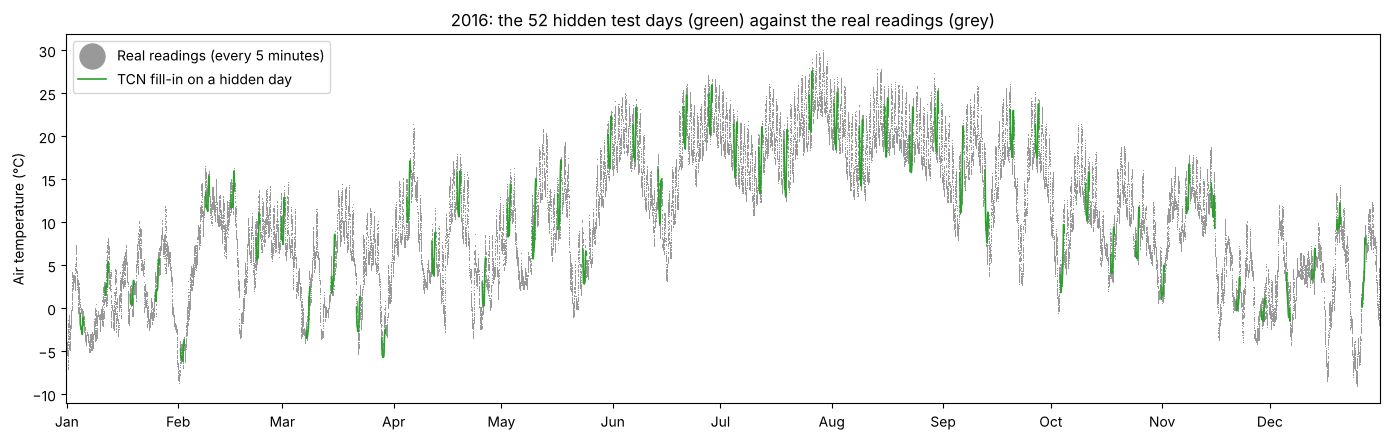

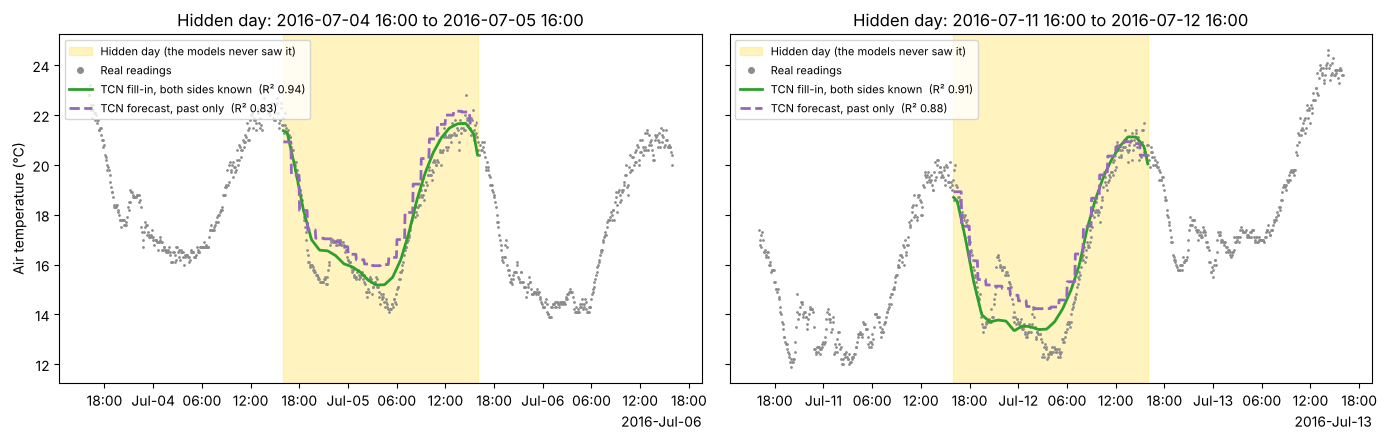

In [7]:
import matplotlib.dates as mdates

start = np.datetime64('2011-01-01T00:00') - np.timedelta64(8, 'h')    # day numbers are UTC; show local time
as_local = lambda days: start + np.round(np.asarray(days) * 1440).astype('timedelta64[m]')
day_of = lambda date: (np.datetime64(date) - np.datetime64('2011-01-01')).astype(int)
tt, p_fill = t[te_r], P_te[:, 3]

# One year: every reading of 2016, and the TCN's fill-in for each hidden test day.
y0, y1 = day_of('2016-01-01'), day_of('2017-01-01')
w = (t >= y0) & (t < y1)
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(as_local(t[w]), temp[w], ',', color='0.6')
ax.plot([], [], '.', color='0.6', label='Real readings (every 5 minutes)')
for i, d in enumerate(np.unique(day_r[te_r & w])):
    m = day_r[te_r] == d
    ax.plot(as_local(tt[m]), p_fill[m], color='tab:green', lw=1.2, label='TCN fill-in on a hidden day' if i == 0 else None)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.set_xlim(as_local(y0), as_local(y1))
ax.set_title('2016: the %d hidden test days (green) against the real readings (grey)' % len(np.unique(day_r[te_r & w])))
ax.set_ylabel('Air temperature (°C)')
ax.legend(loc='upper left', markerscale=6)
plt.tight_layout()
plt.show()

# Zoom: two hidden days in July 2016, each with the day before and the day after.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, d in zip(axes, [day_of('2016-07-05'), day_of('2016-07-12')]):
    d = d - (d - TEST) % 7                           # snap to a test day
    w, m = (t > d - 1) & (t < d + 2), (tt >= d) & (tt < d + 1)
    y, mf = temp[te_r][m], (day_r >= first) & (day_r == d)
    ax.axvspan(as_local(d), as_local(d + 1), color='gold', alpha=0.25, label='Hidden day (the models never saw it)')
    ax.plot(as_local(t[w]), temp[w], '.', ms=2, color='0.55', label='Real readings')
    ax.plot(as_local(tt[m]), p_fill[m], color='tab:green', lw=2,
            label='TCN fill-in, both sides known  (R² %.2f)' % r2(y, p_fill[m]))
    ax.plot(as_local(t[mf]), fc_te_hourly[hour[mf]], color='tab:purple', lw=2, ls='--',
            label='TCN forecast, past only  (R² %.2f)' % r2(temp[mf], fc_te_hourly[hour[mf]]))
    loc = mdates.HourLocator(byhour=[0, 6, 12, 18])
    ax.xaxis.set_major_locator(loc)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
    ax.set_title('Hidden day: %s to %s' % (str(as_local(d))[:16].replace('T', ' '), str(as_local(d + 1))[:16].replace('T', ' ')))
    ax.legend(loc='upper left', fontsize=8, markerscale=4)
axes[0].set_ylabel('Air temperature (°C)')
plt.tight_layout()
plt.show()

## Reading the result

Test days (every 7th day, used once), R² on all 5-minute readings:

| Model | R² | RMSE |
|---|---|---|
| RBF baseline (RBF notebook) | 0.931 | 2.02 °C |
| RBF+ ridge (new transforms) | 0.936 | 1.94 °C |
| XGBoost | 0.914 | 2.26 °C |
| **TCN** | **0.970** | **1.33 °C** |
| Ridge blend of all four | 0.970 | 1.33 °C |

- **The TCN beats the RBF model clearly**: R² 0.931 → 0.970, and the typical error drops by a third (2.02 → 1.33 °C).
  It uses the temperatures on either side of a missing day directly, which the RBF model only does indirectly
  through its fitted bumps. The plot shows the difference: the RBF baseline flattens the night-time lows and
  afternoon highs, the TCN follows them.
- **The new transforms help the ridge model a little** (0.931 → 0.936): the periodic terms and the seasonal
  daily-swing terms add shape the RBFs alone could not make.
- **XGBoost alone is the weakest** (0.914). Trees on time give step-shaped predictions within a missing day.
  It also used all 5,000 trees without early stopping, so more trees might help slightly.
- **The blend adds nothing over the TCN**: it gives the TCN 0.92 of the weight, XGBoost 0.10 and both ridge
  models 0, and scores the same 0.970.

**Fill-in vs forecasting** (same test days, 312 with a full week of history):

| Task | Model | R² | RMSE |
|---|---|---|---|
| Forecast the day from the 7 days before it | Persistence (same time yesterday) | 0.811 | 3.34 °C |
| Forecast the day from the 7 days before it | **TCN forecast** | **0.912** | **2.28 °C** |
| Fill in the day, days on both sides known | TCN fill-in | 0.970 | 1.33 °C |

- **Forecasting is harder, as expected**: knowing the day *after* is worth a lot. The forecasting TCN still beats
  persistence by a wide margin (R² 0.81 → 0.91, error 3.34 → 2.28 °C), because it learns the daily shape and the
  usual drift instead of copying yesterday.
- In the zoomed plot the purple forecast follows the daily cycle but misses the depth of the night-time low; the
  green fill-in can see the next morning's readings and gets closer.
- R² here pools all seasons, so even persistence scores 0.81. The RMSE in °C is the fairer measure of how good a
  single day's prediction is.